# Wine quality: interpretable quality prediction

**Question:** Which measurable chemistry attributes are associated with high-rated red wine?

Source: [UCI Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality). The outcome becomes a practical binary triage label: quality ≥ 7.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, classification_report
from sklearn.model_selection import train_test_split

df = pd.read_csv(Path('../datasets/portfolio-expansion/wine-quality/winequality-red.csv'), sep=';')
y = (df.pop('quality') >= 7).astype(int)
X_train,X_test,y_train,y_test=train_test_split(df,y,test_size=.25,stratify=y,random_state=42)
model=RandomForestClassifier(n_estimators=500,min_samples_leaf=3,class_weight='balanced',random_state=42,n_jobs=-1).fit(X_train,y_train)
proba=model.predict_proba(X_test)[:,1]; pred=(proba>=.5).astype(int)
print('High-quality share:',round(y.mean(),3)); print('PR-AUC:',round(average_precision_score(y_test,proba),3)); print(classification_report(y_test,pred))

High-quality share: 0.136
PR-AUC: 0.819
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       346
           1       0.77      0.69      0.73        54

    accuracy                           0.93       400
   macro avg       0.86      0.83      0.84       400
weighted avg       0.93      0.93      0.93       400



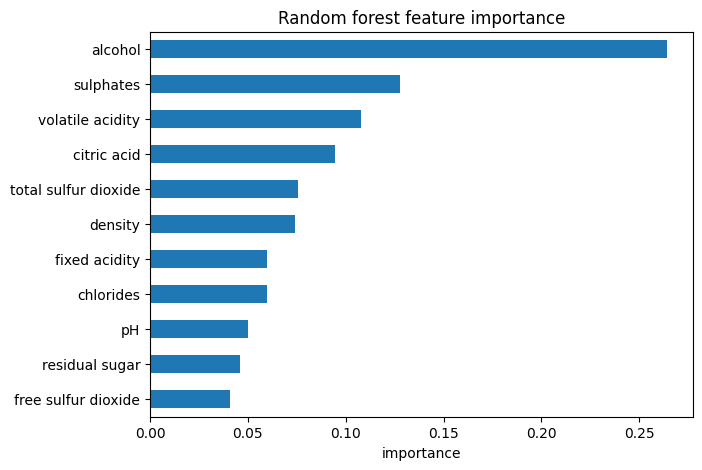

quality,quality < 7,quality ≥ 7
fixed acidity,7.80,8.70
volatile acidity,0.54,0.37
citric acid,0.24,0.40
residual sugar,2.20,2.30
chlorides,0.08,0.07
free sulfur dioxide,14.00,11.00
total sulfur dioxide,39.50,27.00
density,1.00,1.00
pH,3.31,3.27
sulphates,0.60,0.74


In [2]:
# Importances describe the fitted model; they are associations, not causal claims.
importance=pd.Series(model.feature_importances_,index=df.columns).sort_values()
importance.plot.barh(figsize=(7,5),title='Random forest feature importance'); plt.xlabel('importance'); plt.show()
display(df.groupby(y).median().T.rename(columns={0:'quality < 7',1:'quality ≥ 7'}).round(2))

## Portfolio takeaway

This notebook pairs an imbalanced classification metric with model interpretation. Next, use permutation importance and external sensory-panel validation before making production quality decisions.